In [2]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

df = pd.read_pickle('data.pkl')
print(df.head())
print(df.info())

          id  vendor_id     pickup_datetime     dropoff_datetime  \
0  id2875421          2 2016-03-14 17:24:55  2016-03-14 17:32:30   
1  id2377394          1 2016-06-12 00:43:35  2016-06-12 00:54:38   
2  id3858529          2 2016-01-19 11:35:24  2016-01-19 12:10:48   
3  id3504673          2 2016-04-06 19:32:31  2016-04-06 19:39:40   
4  id2181028          2 2016-03-26 13:30:55  2016-03-26 13:38:10   

   passenger_count  pickup_longitude  pickup_latitude  dropoff_longitude  \
0                1        -73.982155        40.767937         -73.964630   
1                1        -73.980415        40.738564         -73.999481   
2                1        -73.979027        40.763939         -74.005333   
3                1        -74.010040        40.719971         -74.012268   
4                1        -73.973053        40.793209         -73.972923   

   dropoff_latitude store_and_fwd_flag  ...  haversine  log_haversine  \
0         40.765602                  N  ...   1.498523       

1. Обучите Ridge-регрессию с параметрами по умолчанию, закодировав все 
категориальные признаки с помощью OneHotEncoder. Численные признаки 
отмасштабируйте с помощью StandardScaler. Используйте только признаки: День 
недели, Месяц, Час, Является ли период аномальным (два бинарных признака, 
соответствующие двум аномальным периодам), Номер дня в году. 

In [29]:
features_1 = [
    'day_of_week',
    'month',
    'hour',
    'anom_period1',
    'anom_period2',
    'day_of_year'
]

X1 = df[features_1]

y = df['log_trip_duration']

cat_features_1 = ['day_of_week', 'month', 'hour']
num_features_1 = ['anom_period1', 'anom_period2', 'day_of_year']

preprocessor_1 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_1),
        ('num', StandardScaler(), num_features_1)
    ]
)

model_1 = Pipeline([
    ('preprocessor', preprocessor_1),
    ('regressor', Ridge())
])

# обучение

X_train, X_test, y_train, y_test = train_test_split(X1, y, test_size=0.8, random_state=42)

model_1.fit(X_train, y_train)

y_pred_1 = model_1.predict(X_test)

print(f"MSE (model 1): {mean_squared_error(y_test, y_pred_1):.4f}")


MSE (model 1): 0.6228


2. Обучите Ridge-регрессию со стандартными параметрами на признаках из 
пунктов 17-25 Задания 1. Категориальные признаки закодируйте через one-hot
кодирование, численные признаки отмасштабируйте. 

In [28]:
features_2 = [
    'haversine',
    'log_haversine',
    'passenger_count',
    'is_rush_hour',
    'is_free_road',
    'vendor_id',
    'store_and_fwd_flag',
    
    # географические флаги
    'pickup_chelsea',
    'dropoff_jfk'
]

cat_features_2 = [
    'vendor_id',
    'store_and_fwd_flag'
]

num_features_2 = [
    'haversine',
    'log_haversine',
    'passenger_count',
    'is_rush_hour',
    'is_free_road',
    'pickup_chelsea',
    'dropoff_jfk'
]

X2 = df[features_2]
y = df['log_trip_duration']

preprocessor_2 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_2),
        ('num', StandardScaler(), num_features_2)
    ]
)

model_2 = Pipeline([
    ('preprocessor', preprocessor_2),
    ('regressor', Ridge())
])

X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

model_2.fit(X_train, y_train)

y_pred_2 = model_2.predict(X_test)

print(f"MSE (model 2): {mean_squared_error(y_test, y_pred_2):.4f}")

MSE (model 2): 0.2490


3. Обучайте Ridge-регрессию со стандартными параметрами с учетом признаков 
vendor_id, passenger_count и store_and_fwd_flag. Категориальные признаки 
закодируйте one-hot-кодированием, а численные отмасштабируйте. Будут ли эти 
признаки сильными? 

In [26]:
features_3 = [
    'vendor_id',
    'passenger_count',
    'store_and_fwd_flag'
]

X3 = df[features_3]
y = df['log_trip_duration']

cat_features_3 = ['vendor_id', 'store_and_fwd_flag']
num_features_3 = ['passenger_count']

preprocessor_3 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_3),
        ('num', StandardScaler(), num_features_3)
    ]
)

model_3 = Pipeline([
    ('preprocessor', preprocessor_3),
    ('regressor', Ridge())
])

X_train, X_test, y_train, y_test = train_test_split(X3, y, test_size=0.2, random_state=42)

model_3.fit(X_train, y_train)

y_pred_3 = model_3.predict(X_test)

print(f"MSE (model 3): {mean_squared_error(y_test, y_pred_3):.4f}")

MSE (model 3): 0.6353


Почему модель плоха: признаки слабые.

Почему:

vendor_id - всего 2 категории, почти не влияет

store_and_fwd_flag - почти всегда N, мало информации

passenger_count - слабо связан со временем поездки

По итогу:

модель почти не понимает, от чего зависит время поездки

4. Очистите выборку от выбросов. В категориальных признаках могут содержаться 
редкие категории, обычно это плохо: модель сильно переобучается на таких 
примерах. Попробуйте объединить редкие категории для категориальных 
признаков в одну. 

In [12]:
df_clean = df[
    (df['trip_duration'] > 60) &          # больше 1 минуты
    (df['trip_duration'] < 3600*2) &      # меньше 2 часов
    (df['haversine'] > 0.1) &             # не нулевое расстояние
    (df['haversine'] < 50)                # адекватный предел
]

# OneHotEncoder создаёт колонку для каждой категории, если категория встречается 5 раз, то модель переобучается

df_clean['store_and_fwd_flag'] = df_clean['store_and_fwd_flag'].replace(
    df_clean['store_and_fwd_flag'].value_counts()[lambda x: x < 100].index,
    'rare'
)

df_clean['vendor_id'] = df_clean['vendor_id'].astype(str)


Были удалены поездки с аномально малой и большой длительностью, а также с нереалистичным расстоянием.
Это позволяет уменьшить влияние шумовых данных на модель.

Редкие категории были объединены в одну группу "rare", так как модели склонны переобучаться на малочастотных значениях.

5. Попробуйте обучить не Ridge-, а Lasso-регрессию. Сравните результаты с 
предыдущими результатами обучения.

In [25]:
X2_clean = df_clean[features_2]
y_clean = np.log(df_clean['trip_duration'])

X_train, X_test, y_train, y_test = train_test_split(
    X2_clean, y_clean, test_size=0.2, random_state=42
)

model_lasso = Pipeline([
    ('preprocessor', preprocessor_2),
    ('regressor', Lasso(max_iter=10000))
])

model_lasso.fit(X_train, y_train)

y_pred_lasso = model_lasso.predict(X_test)

print(f"MSE (Lasso): {mean_squared_error(y_test, y_pred_lasso):.4f}")

MSE (Lasso): 0.5287


Lasso-регрессия выполняет отбор признаков, зануляя часть коэффициентов.
В отличие от Ridge, она может ухудшать качество, если признаки важны,
но позволяет упростить модель.

6. Разбейте обучающую выборку на обучающую и валидационную в отношении 8:2. 
По валидационной выборке подберите оптимальное значение параметра 
регуляризации (по логарифмической сетке), на тестовой выборке измерьте 
качество полученной модели. 

In [24]:
# данные 80/20
X_train_full, X_test, y_train_full, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

alphas = np.logspace(-4, 1, 20)

val_scores = []

for alpha in alphas:
    model = Pipeline([
        ('preprocessor', preprocessor_2),
        ('regressor', Lasso(alpha=alpha, max_iter=10000))
    ])
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    
    mse = mean_squared_error(y_val, y_pred)
    val_scores.append(mse)

best_alpha = alphas[np.argmin(val_scores)]

print(f"Лучшая альфа: {best_alpha:.10f}")

final_model = Pipeline([
    ('preprocessor', preprocessor_2),
    ('regressor', Lasso(alpha=best_alpha, max_iter=10000))
])

final_model.fit(X_train_full, y_train_full)

y_pred = final_model.predict(X_test)

print(f"Конечный MSE: {mean_squared_error(y_test, y_pred):.4f}")


Лучшая альфа: 0.0001000000
Конечный MSE: 0.2490


7. Для каждого перебранного alpha посчитайте количество нулевых весов в модели и нарисуйте график зависимости его от alpha. 

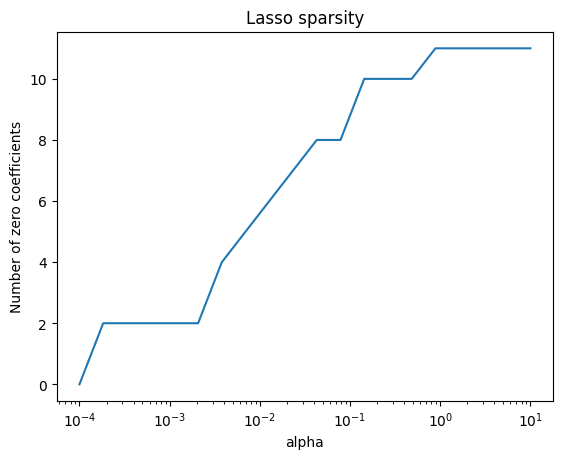

In [17]:
zero_counts = []

for alpha in alphas:
    model = Pipeline([
        ('preprocessor', preprocessor_2),
        ('regressor', Lasso(alpha=alpha, max_iter=10000))
    ])
    
    model.fit(X_train, y_train)
    
    coefs = model.named_steps['regressor'].coef_
    zero_counts.append(np.sum(coefs == 0))

plt.plot(alphas, zero_counts)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Number of zero coefficients')
plt.title('Lasso sparsity')
plt.show()


При увеличении alpha количество нулевых коэффициентов растёт,
что означает усиление регуляризации и упрощение модели.

8. Разбейте карту на ячейки. Количество строк и столбцов выберите 
самостоятельно. Создайте два признака: номер ячейки, в которой началась 
поездка, и номер ячейки, в которой закончилась поездка. Посчитайте, сколько 
раз встречается каждая возможная пара этих признаков и выберите 100 самых 
частых пар. Закодируйте поездки с этими редкими парами как категориальный 
признак, остальным объектам припишем -1. Получается, что мы закодировали, 
откуда и куда должно было ехать такси. Почему такой признак потенциально 
полезный? Почему линейная модель не может самостоятельно "вытащить" эту 
информацию, ведь у нее в распоряжении есть признаки "из какой ячейки 
началась поездка" и "в какой ячейке закончилась поездка"? 

In [ ]:
# Шаг 1: сетка
n_bins = 20

df['pickup_bin_x'] = pd.cut(df['pickup_longitude'], bins=n_bins, labels=False)
df['pickup_bin_y'] = pd.cut(df['pickup_latitude'], bins=n_bins, labels=False)

df['dropoff_bin_x'] = pd.cut(df['dropoff_longitude'], bins=n_bins, labels=False)
df['dropoff_bin_y'] = pd.cut(df['dropoff_latitude'], bins=n_bins, labels=False)

# Шаг 2: создаём ID ячейки
df['pickup_cell'] = df['pickup_bin_x'] * n_bins + df['pickup_bin_y']
df['dropoff_cell'] = df['dropoff_bin_x'] * n_bins + df['dropoff_bin_y']

# Шаг 3: пары
df['route'] = df['pickup_cell'].astype(str) + '_' + df['dropoff_cell'].astype(str)

# Шаг 4: топ-100 маршрутов
top_routes = df['route'].value_counts().head(100).index

df['route_top'] = df['route'].apply(lambda x: x if x in top_routes else 'rare')


' Ответ\nПочему признак полезен:\nОн напрямую кодирует маршрут поездки, что сильно влияет на её длительность.\n\nПочему линейная модель сама не "понимает":\nЛинейная модель учитывает признаки независимо.\nОна не умеет автоматически учитывать взаимодействие между признаками\n(откуда И куда), если оно явно не задано.'

Почему признак полезен: он напрямую кодирует маршрут поездки, что сильно влияет на её длительность.
Почему линейная модель сама не "понимает":
Линейная модель учитывает признаки независимо.
Она не умеет автоматически учитывать взаимодействие между признаками
(откуда И куда), если оно явно не задано.

9. Переобучите модель на новых данных и посчитайте качество.

In [23]:
# признаки
features_2_new = features_2.copy()
features_2_new.append('route_top')

cat_features_2_new = cat_features_2.copy()
cat_features_2_new.append('route_top')

X_new = df[features_2_new]
y = df['log_trip_duration']

# численные признаки
num_features_2_new = [col for col in features_2_new if col not in cat_features_2_new]

# препроцессинг
preprocessor_new = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features_2_new),
        ('num', StandardScaler(), num_features_2_new)
    ]
)

# модель (Ridge!)
model_new = Pipeline([
    ('preprocessor', preprocessor_new),
    ('regressor', Ridge())
])

# обучение
X_train, X_test, y_train, y_test = train_test_split(
    X_new, y, test_size=0.2, random_state=42
)

model_new.fit(X_train, y_train)

y_pred = model_new.predict(X_test)
print(f"MSE (с рутами): {mean_squared_error(y_test, y_pred):.4f}")


MSE (с рутами): 0.2481


10. Какие признаки дают наилучший результат? 

Наибольший вклад в качество модели вносят:
- расстояние (haversine, log_haversine)
- маршрут поездки (route)
- географические признаки (pickup/dropoff зоны)

Менее полезны:
- vendor_id
- store_and_fwd_flag
- passenger_count